<a href="https://colab.research.google.com/github/smir-nat/Mat-model/blob/main/lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

2.1.1. Передатні функції лінійних ланок

In [ ]:
import scipy.signal as signal
import numpy as np

num = [2, -5, 2]
den = [2, 1, 12, 1]

# Знаходження нулів, полюсів та коефіцієнта підсилення (zpk-форма)
zeros, poles, gain = signal.tf2zpk(num, den)

print("Нулі системи (Zeros):", np.round(zeros, 4))
print("Полюси системи (Poles):", np.round(poles, 4))
print("Коефіцієнт підсилення (Gain):", gain)
is_stable = all(np.real(p) < 0 for p in poles)

if is_stable:
    print("\nВисновок: Система СТІЙКА.")
else:
    print("\nВисновок: Система НЕСТІЙКА.")

Нулі системи (Zeros): [2.  0.5]
Полюси системи (Poles): [-0.2081+2.4335j -0.2081-2.4335j -0.0838+0.j    ]
Коефіцієнт підсилення (Gain): 1.0

Висновок: Система СТІЙКА.


<>:49: SyntaxWarning: invalid escape sequence '\o'
<>:49: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_849/3362162513.py:49: SyntaxWarning: invalid escape sequence '\o'
  axs[2].set_title(f'Відгук на гармонічний сигнал ($\omega={omega}$ рад/с)')


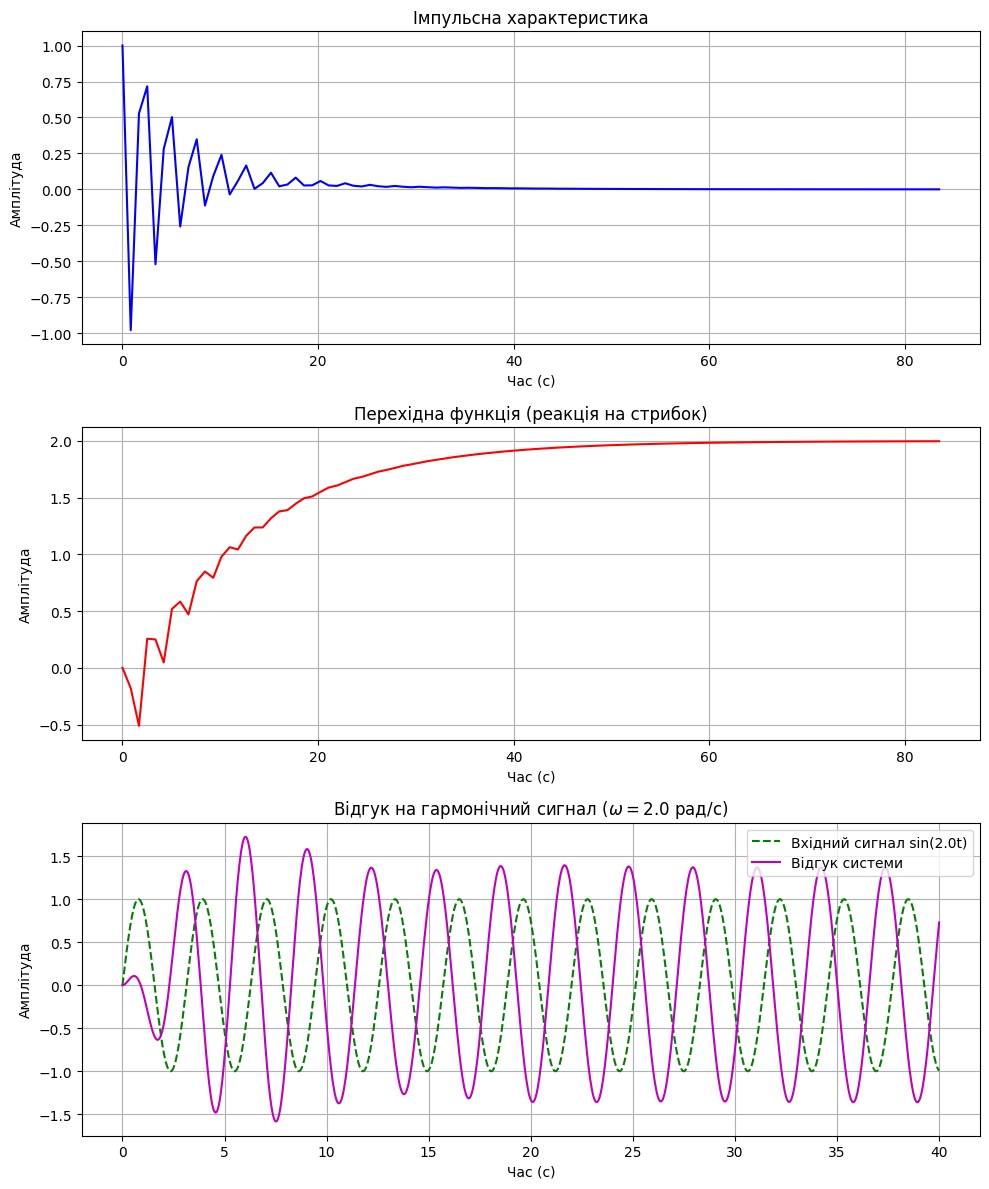

Аналіз для гармонічного сигналу з частотою ω = 2.0 рад/с:
Коефіцієнт посилення (зміна амплітуди): 1.3649
Зсув фази: 2.2424 рад (128.48°)


In [ ]:
import scipy.signal as signal
import numpy as np
import matplotlib.pyplot as plt

num = [2, -5, 2]
den = [2, 1, 12, 1]
sys = signal.TransferFunction(num, den)

t_imp, y_imp = signal.impulse(sys)
t_step, y_step = signal.step(sys)

omega = 2.0
t_harm = np.linspace(0, 40, 1000)
u_harm = np.sin(omega * t_harm)
t_out, y_harm, _ = signal.lsim(sys, U=u_harm, T=t_harm)

w, H = signal.freqresp(sys, w=[omega])
magnitude_gain = np.abs(H[0])
phase_shift_rad = np.angle(H[0])
phase_shift_deg = np.degrees(phase_shift_rad)

fig, axs = plt.subplots(3, 1, figsize=(10, 12))

axs[0].plot(t_imp, y_imp, 'b')
axs[0].set_title('Імпульсна характеристика')
axs[0].set_xlabel('Час (с)')
axs[0].set_ylabel('Амплітуда')
axs[0].grid(True)

axs[1].plot(t_step, y_step, 'r')
axs[1].set_title('Перехідна функція (реакція на стрибок)')
axs[1].set_xlabel('Час (с)')
axs[1].set_ylabel('Амплітуда')
axs[1].grid(True)

axs[2].plot(t_harm, u_harm, 'g--', label=f'Вхідний сигнал sin({omega}t)')
axs[2].plot(t_out, y_harm, 'm', label='Відгук системи')
axs[2].set_title(f'Відгук на гармонічний сигнал ($\omega={omega}$ рад/с)')
axs[2].set_xlabel('Час (с)')
axs[2].set_ylabel('Амплітуда')
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()

print(f"Аналіз для гармонічного сигналу з частотою ω = {omega} рад/с:")
print(f"Коефіцієнт посилення (зміна амплітуди): {magnitude_gain:.4f}")
print(f"Зсув фази: {phase_shift_rad:.4f} рад ({phase_shift_deg:.2f}°)")

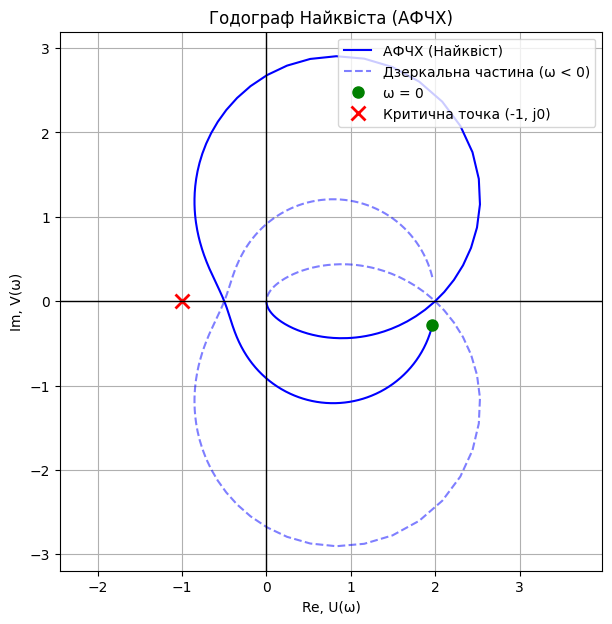

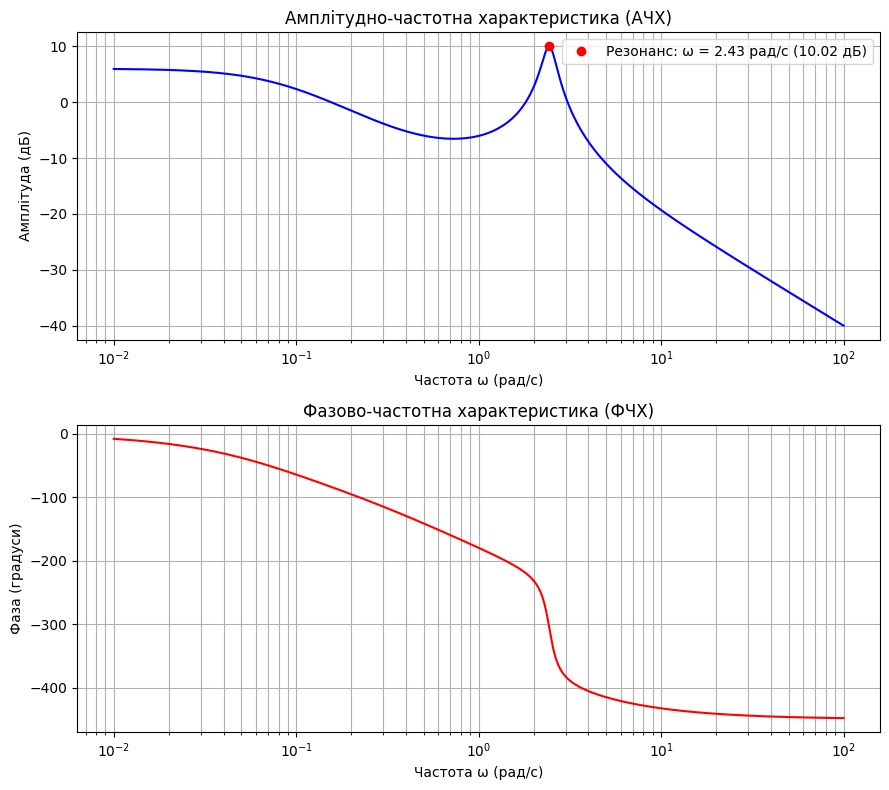

In [1]:
import scipy.signal as signal
import numpy as np
import matplotlib.pyplot as plt

num = [2, -5, 2]
den = [2, 1, 12, 1]
sys = signal.TransferFunction(num, den)

w = np.logspace(-2, 2, 1000)
w, H = signal.freqresp(sys, w=w)

plt.figure(figsize=(7, 7))
plt.plot(H.real, H.imag, 'b-', label='АФЧХ (Найквіст)')
plt.plot(H.real, -H.imag, 'b--', alpha=0.5, label='Дзеркальна частина (ω < 0)')
plt.plot(H[0].real, H[0].imag, 'go', markersize=8, label='ω = 0')
plt.plot(-1, 0, 'rx', markersize=10, markeredgewidth=2, label='Критична точка (-1, j0)')

plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.grid(True)
plt.xlabel('Re, U(ω)')
plt.ylabel('Im, V(ω)')
plt.title('Годограф Найквіста (АФЧХ)')
plt.legend()
plt.axis('equal')
plt.show()

w_bode, mag_db, phase_deg = signal.bode(sys, w=w)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8))

ax1.semilogx(w_bode, mag_db, 'b')
ax1.set_title('Амплітудно-частотна характеристика (АЧХ)')
ax1.set_xlabel('Частота ω (рад/с)')
ax1.set_ylabel('Амплітуда (дБ)')
ax1.grid(True, which="both")

res_idx = np.argmax(mag_db)
w_res = w_bode[res_idx]
mag_res = mag_db[res_idx]
ax1.plot(w_res, mag_res, 'ro', label=f'Резонанс: ω = {w_res:.2f} рад/с ({mag_res:.2f} дБ)')
ax1.legend()

ax2.semilogx(w_bode, phase_deg, 'r')
ax2.set_title('Фазово-частотна характеристика (ФЧХ)')
ax2.set_xlabel('Частота ω (рад/с)')
ax2.set_ylabel('Фаза (градуси)')
ax2.grid(True, which="both")

plt.tight_layout()
plt.show()

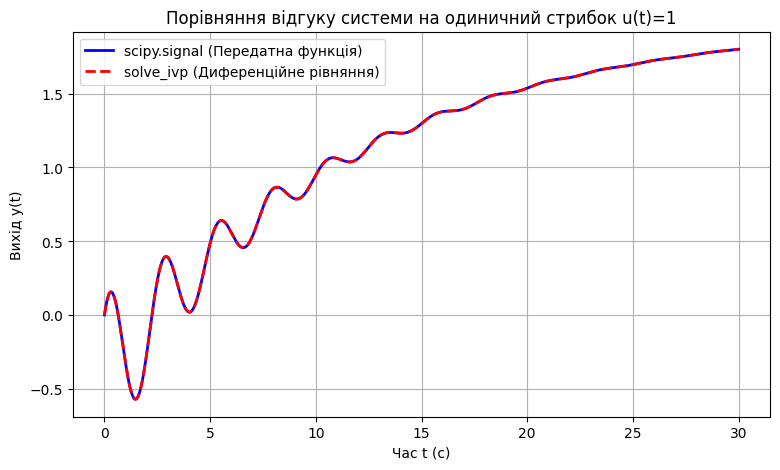

Максимальна абсолютна різниця між розв'язками: 9.424285e-04


In [2]:
import numpy as np
import scipy.signal as signal
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

num = [2, -5, 2]
den = [2, 1, 12, 1]
sys = signal.TransferFunction(num, den)

t_eval = np.linspace(0, 30, 1000)
t_tf, y_tf = signal.step(sys, T=t_eval)

def ode_system(t, x):
    u = 1.0
    x1, x2, x3 = x
    dx1_dt = x2
    dx2_dt = x3
    dx3_dt = -0.5 * x1 - 6.0 * x2 - 0.5 * x3 + 0.5 * u
    return [dx1_dt, dx2_dt, dx3_dt]

x0 = [0.0, 0.0, 0.0]

sol = solve_ivp(ode_system, [0, 30], x0, t_eval=t_eval)
y_ode = 2 * sol.y[2] - 5 * sol.y[1] + 2 * sol.y[0]

plt.figure(figsize=(9, 5))
plt.plot(t_tf, y_tf, 'b-', linewidth=2, label='scipy.signal (Передатна функція)')
plt.plot(sol.t, y_ode, 'r--', linewidth=2, label='solve_ivp (Диференційне рівняння)')
plt.title('Порівняння відгуку системи на одиничний стрибок u(t)=1')
plt.xlabel('Час t (с)')
plt.ylabel('Вихід y(t)')
plt.grid(True)
plt.legend()
plt.show()

max_diff = np.max(np.abs(y_tf - y_ode))
print(f"Максимальна абсолютна різниця між розв'язками: {max_diff:.6e}")

2.1.2. Задача реалізації

--- Перевірка відновлених передатних функцій ---
З КФК: [[ 0.   1.  -2.5  1. ]] / [1.  0.5 6.  0.5]
З КФС: [[ 0.   1.  -2.5  1. ]] / [1.  0.5 6.  0.5]


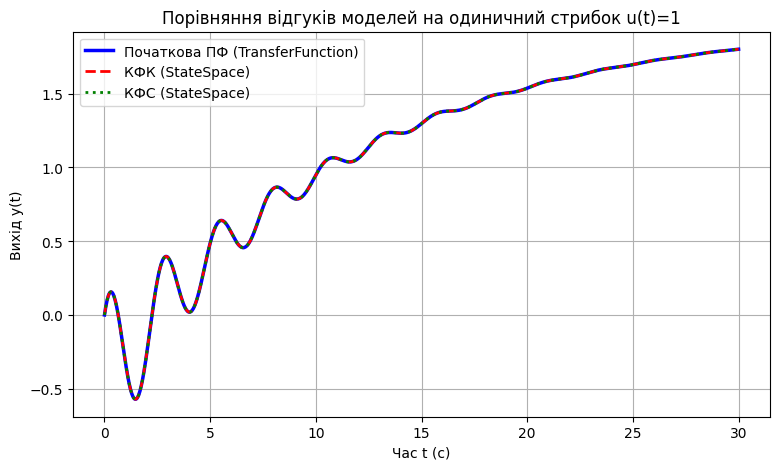

Максимальна різниця ПФ vs КФК: 3.108624e-15
Максимальна різниця ПФ vs КFS: 6.616929e-14


In [3]:
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

num = [2, -5, 2]
den = [2, 1, 12, 1]
sys_tf = signal.TransferFunction(num, den)

a2, a1, a0 = 0.5, 6.0, 0.5
b2, b1, b0 = 1.0, -2.5, 1.0

A_c = np.array([[0, 1, 0],
                [0, 0, 1],
                [-a0, -a1, -a2]])
B_c = np.array([[0], [0], [1]])
C_c = np.array([[b0, b1, b2]])
D_c = np.array([[0]])

sys_kfk = signal.StateSpace(A_c, B_c, C_c, D_c)

A_o = A_c.T
B_o = C_c.T
C_o = B_c.T
D_o = np.array([[0]])

sys_kfs = signal.StateSpace(A_o, B_o, C_o, D_o)

tf_from_kfk = signal.ss2tf(A_c, B_c, C_c, D_c)
tf_from_kfs = signal.ss2tf(A_o, B_o, C_o, D_o)

print("--- Перевірка відновлених передатних функцій ---")
print("З КФК:", np.round(tf_from_kfk[0], 4), "/", np.round(tf_from_kfk[1], 4))
print("З КФС:", np.round(tf_from_kfs[0], 4), "/", np.round(tf_from_kfs[1], 4))

t_eval = np.linspace(0, 30, 1000)

t_tf, y_tf = signal.step(sys_tf, T=t_eval)
t_kfk, y_kfk = signal.step(sys_kfk, T=t_eval)
t_kfs, y_kfs = signal.step(sys_kfs, T=t_eval)

plt.figure(figsize=(9, 5))
plt.plot(t_tf, y_tf, 'b-', linewidth=2.5, label='Початкова ПФ (TransferFunction)')
plt.plot(t_kfk, y_kfk, 'r--', linewidth=2, label='КФК (StateSpace)')
plt.plot(t_kfs, y_kfs, 'g:', linewidth=2, label='КФС (StateSpace)')

plt.title('Порівняння відгуків моделей на одиничний стрибок u(t)=1')
plt.xlabel('Час t (с)')
plt.ylabel('Вихід y(t)')
plt.grid(True)
plt.legend()
plt.show()

diff_kfk = np.max(np.abs(y_tf - y_kfk))
diff_kfs = np.max(np.abs(y_tf - y_kfs))
print(f"Максимальна різниця ПФ vs КФК: {diff_kfk:.6e}")
print(f"Максимальна різниця ПФ vs КFS: {diff_kfs:.6e}")